In [1]:
import subprocess
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR=Path(r"C:\Users\HP Omen\Documents\cpp\modeling")
CPP_EXE=PROJECT_DIR/"08.exe"
N=2000
dt=0.01
phi0=1
omega=1
gamma=0.2
params={"N":N,"dt":dt,"phi0":phi0,"omega":omega,"gamma":gamma}

p=subprocess.run([str(CPP_EXE)],input=json.dumps(params),capture_output=True,text=True)

OUTPUT_DAT=PROJECT_DIR/"08.dat"
data=np.loadtxt(OUTPUT_DAT)
tau=data[:,0]
phi1=data[:,1]
phi2=data[:,2]
phi3=data[:,3]
w1=data[:,4]
w2=data[:,5]
w3=data[:,6]
E1=data[:,7]
E2=data[:,8]
phi4=data[:,9]

In [2]:
def analytic(t,phi0,omega,gamma):
    if gamma<omega:
        wd=np.sqrt(omega**2 - gamma**2)
        return np.exp(-gamma*t)*(phi0*np.cos(wd*t) + ((gamma*phi0)/wd)*np.sin(wd*t)
        )
    elif gamma==omega:
        return np.exp(-gamma*t)*(phi0+(gamma*phi0)*t)
    else:
        s=np.sqrt(gamma**2-omega**2)
        A=phi0*(gamma+s)/(2*s)
        B=phi0*(s-gamma)/(2*s)
        return A*np.exp((-gamma+s)*t)+B*np.exp((-gamma-s)*t)

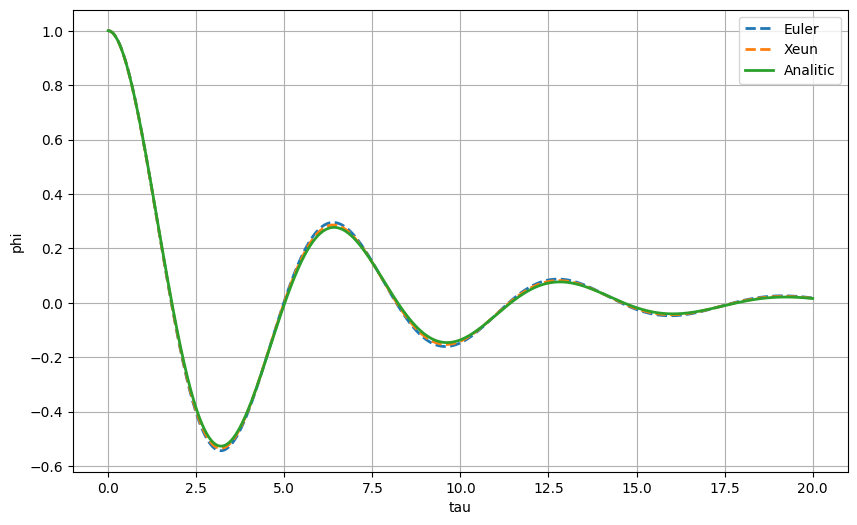

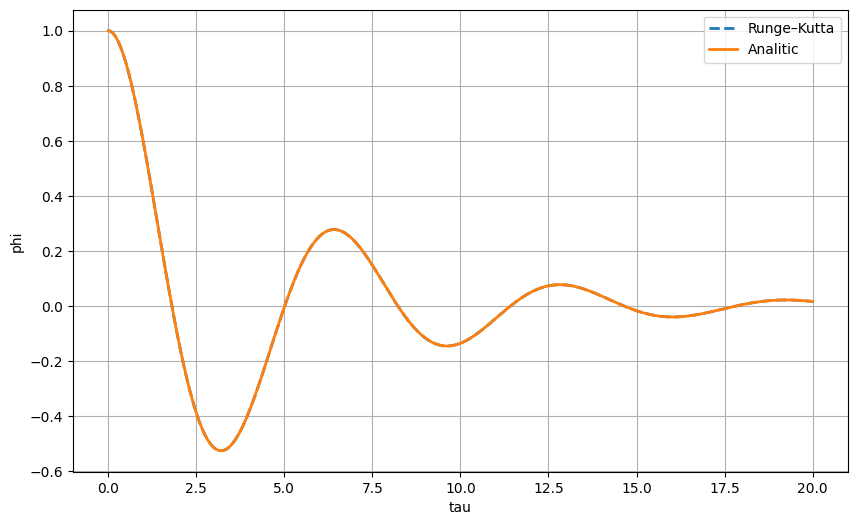

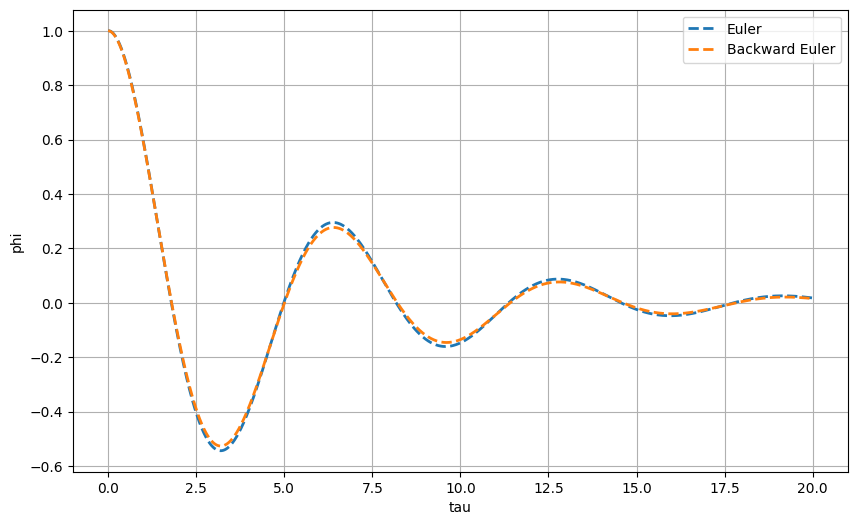

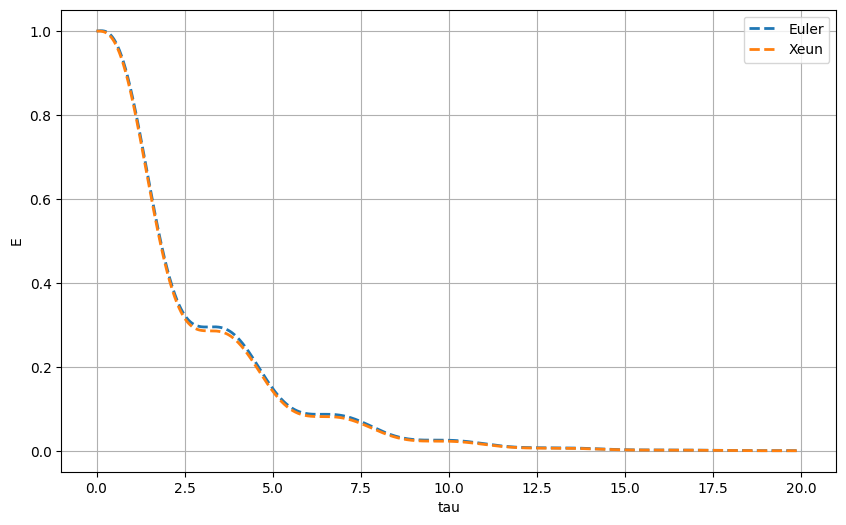

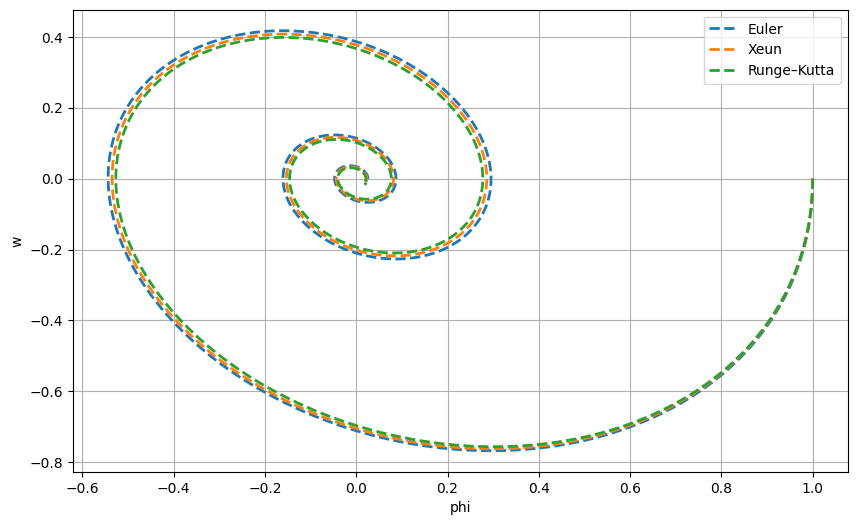

In [3]:
plt.figure(figsize=(10,6))
plt.plot(tau,phi1,label='Euler',linewidth=2,linestyle='--')
plt.plot(tau,phi2,label='Xeun',linewidth=2,linestyle='--')
plt.plot(tau,analytic(tau,phi0,omega,gamma),label='Analitic',linewidth=2)
plt.xlabel('tau')
plt.ylabel('phi')
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(10,6))
plt.plot(tau,phi3,label='Runge–Kutta',linewidth=2,linestyle='--')
plt.plot(tau,analytic(tau,phi0,omega,gamma),label='Analitic',linewidth=2)
plt.xlabel('tau')
plt.ylabel('phi')
plt.grid(True)
plt.legend()
plt.show()


plt.figure(figsize=(10,6))
plt.plot(tau,phi1,label='Euler',linewidth=2,linestyle='--')
plt.plot(tau,phi4,label='Backward Euler',linewidth=2,linestyle='--')
plt.xlabel('tau')
plt.ylabel('phi')
plt.grid(True)
plt.legend()
plt.show()


plt.figure(figsize=(10,6))
plt.plot(tau,E1,label='Euler',linewidth=2,linestyle='--')
plt.plot(tau,E2,label='Xeun',linewidth=2,linestyle='--')
plt.xlabel('tau')
plt.ylabel('E')
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(10,6))
plt.plot(phi1,w1,label='Euler',linewidth=2,linestyle='--')
plt.plot(phi2,w2,label='Xeun',linewidth=2,linestyle='--')
plt.plot(phi3,w3,label='Runge–Kutta',linewidth=2,linestyle='--')
plt.xlabel('phi')
plt.ylabel('w')
plt.grid(True)
plt.legend()
plt.show()